# 01 — Neural NARX station-keeping: reproducible 365-day paired experiment

This notebook generates STM teacher trajectories, preserves the gradient-boosted baseline,
trains a genuine `narxpy` neural NARX, evaluates independent held-out arcs, and executes
uncontrolled, STM, gradient-boosted and neural controllers in the nonlinear Earth–Moon CR3BP.
Notebook 00 and all its original visualizations are unchanged.

Run from a checkout after `python -m pip install -e ".[dev,neural-narx]"`.
Every run regenerates the dataset and trains both policies before the annual simulation.
Outputs, weights, paired noise arrays, metrics and PNG figures are saved under
`artifacts/neural_narx/`. Five paired trials are an exploratory Monte Carlo experiment,
not a validated estimate of operational reliability.

In [1]:
from pathlib import Path
import os, json, sys, hashlib, platform
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT/'configs').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
from halo_tracking.study import load_config
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset
from halo_tracking.two_stage_narx import fit_observer_policy, evaluate_two_stage
from halo_tracking.neural_narx import fit_neural_policy
from halo_tracking.narx_audit import audit_dataset
from halo_tracking.year_study import run_paired_study
YEAR_DAYS = 365
MC_ARCS = 5
OUT = ROOT/'artifacts'/'neural_narx'
OUT.mkdir(parents=True, exist_ok=True)
cfg = load_config()
cfg['narx']['closed_loop_measurement_cadence_s'] = 21600.
nb00 = ROOT/'notebooks'/'00_gateway_tracking_comparison.ipynb'
nb00_hash = hashlib.sha256(nb00.read_bytes()).hexdigest()
print('Python:', platform.python_version(), 'annual trials:', MC_ARCS)
print('Independent training/validation/test arcs:', [cfg['narx'][s+'_arcs'] for s in ('training','validation','test')])

Python: 3.14.8 annual trials: 5
Independent training/validation/test arcs: [20, 5, 5]


## NARX equations, architecture and causal interpretation

Let $x_k\in\mathbb R^{11}$ contain the current estimated observer departure
(three MCI position components in km and three MCI velocity components in m/s),
$\sin\phi_k,\cos\phi_k$, Gateway visibility, visible LSO count, and
$\log_{10}\operatorname{tr}P_{rr}$ in normalized CR3BP coordinates.
The output $y_k\in\mathbb R^8$ comprises an execute score, three rotating-frame
impulse components in m/s, and four delay scores. Valid STM commands have
execute=1 and a one-hot delay; no-burn, pending and rejected labels are zero.

With training-only standardization denoted by a tilde,
$$\hat{\tilde y}_k=W_2\tanh\left(W_1[\tilde x_{k-3},\ldots,\tilde x_k,
\tilde y_{k-4},\ldots,\tilde y_{k-1}]+b_1\right)+b_2.$$
There are 4 input taps, 4 strictly past output taps, a 76-dimensional concatenated
input, 64 tanh hidden units, and 8 linear outputs (5,448 trainable parameters).
This is `narxpy.NARX(d_i=4,d_o=4,d_x=11,d_y=8,d_hl=64,act_func="Identity")`.
The library uses input indices $k-4:k-1$; a one-step sequence shift gives the
current-measurement convention above without exposing a future measurement.

Training uses true **past** commands (series-parallel/teacher forcing), standardized
MSE, Adam, gradient clipping, 600 epochs, and the minimum validation-loss checkpoint.
Recursive evaluation and physical deployment use previous **predicted** network outputs,
with zero-command warmup for the first four decisions. Pending decisions feed back zero,
matching the teacher's issued-command convention. Raw predicted scores are fed back;
the actuator decoder uses execute > 0.5 and argmax delay. Invalid/nonfinite or over-cap
commands are rejected, never clipped and never replaced with STM control.
The neural network is a command policy, not a CR3BP dynamics surrogate.

The baseline retains its original gradient-boosted classifier, three impulse regressors,
and delay classifier, with lagged navigation and **executed** impulse features. That
baseline is distinct from a neural NARX and is labeled accordingly in every plot.

## Teacher generation and consistency audit

The teacher computes rotating-frame impulses from a terminal-state STM solve, with
km/m/s residual weights and a common terminal horizon across candidate delays. Each
candidate is checked by nonlinear propagation and must improve departure without
exceeding 10 m/s. Only observer burns are applied; Gateway follows the same closure-verified
periodic reference during training and annual deployment. Navigation uses the LSO/Gateway EKF.

Training, validation and test use independent trajectory-level random streams, never a row split.
The audit checks exact decision spacing, MCI input conversion, rotating impulse units,
finite feasible targets, delay membership, history indexing, and dataset configuration. It independently replays every feasible target through nonlinear dynamics and verifies that scheduled targets equal executed teacher burns.
Measurements occur every six hours **plus decision epochs**, exactly as in deployment.
Annual decisions remain exactly one eighth of an observer period; day 365 is an evaluation-only
endpoint when off-grid. A delayed burn can suppress the next decision for all controllers.
The first four learned-controller decisions are warmup; STM is available from day zero.
This startup difference is part of the tested deployment policy.

In [2]:
dataset = OUT/'teacher_training'
dataset_summary = generate_closed_loop_dataset(cfg, dataset)
audit = audit_dataset(dataset, cfg)
(OUT/'audit.json').write_text(json.dumps(audit, indent=2))
display(audit)
baseline = fit_observer_policy(dataset, cfg, OUT/'gradient_boosted.joblib')
baseline_metrics = evaluate_two_stage(dataset, OUT/'baseline_offline', cfg)
neural, neural_metrics = fit_neural_policy(dataset, cfg, OUT/'neural', epochs=600)
print('Network trained:', neural_metrics['epochs_trained'], 'epochs; selected:', neural_metrics['selected_epoch'])
print('Trainable parameters:', sum(p.numel() for p in neural['network'].parameters()))

Network trained: 600 epochs; selected: 110
Trainable parameters: 5448


{'training': {'nonlinear_targets_replayed': 59,
  'applied_targets_verified': True,
  'arcs': 20,
  'history_steps': 4,
  'feasible_burns': 59,
  'rejected_teacher_labels': 0,
  'decision_spacing_days': 1.007259102764151,
  'measurement_cadence_s': 21600.0,
  'input_units': 'MCI departure km,m/s; phase/visibility/count/log normalized covariance',
  'target_units': 'rotating-frame delta-v m/s; delay TU',
  'causal_histories_verified': True},
 'validation': {'nonlinear_targets_replayed': 13,
  'applied_targets_verified': True,
  'arcs': 5,
  'history_steps': 4,
  'feasible_burns': 13,
  'rejected_teacher_labels': 0,
  'decision_spacing_days': 1.007259102764151,
  'measurement_cadence_s': 21600.0,
  'input_units': 'MCI departure km,m/s; phase/visibility/count/log normalized covariance',
  'target_units': 'rotating-frame delta-v m/s; delay TU',
  'causal_histories_verified': True},
 'test': {'nonlinear_targets_replayed': 14,
  'applied_targets_verified': True,
  'arcs': 5,
  'history_steps

## Held-out prediction metrics

No held-out trajectory is used for scaling, gradient fitting or baseline fitting.
Validation selects the neural checkpoint; the test split is evaluated after selection.
Teacher-forced and recursive neural scores are both reported: the latter exposes accumulation
of prediction errors while still using held-out teacher navigation inputs, so it is **not**
a substitute for the physical closed-loop experiment. Neural execute metrics refer to feasible
commands; baseline trigger metrics include rejected teacher requests, so their classification
scores have different label semantics. Feasible-burn impulse RMSE and timing accuracy are
reported separately from all-command RMSE (which includes no-burn examples).

{'gradient_boosted': {'observer': {'status': 'evaluated',
   'training_decisions': 260,
   'training_triggered': 41,
   'training_feasible_triggered': 41,
   'validation': {'evaluated_decisions': 65,
    'positive_rate': 0.12307692307692308,
    'maneuver_precision': 0.8571428571428571,
    'maneuver_recall': 0.75,
    'maneuver_f1': 0.8,
    'confusion_matrix_true_rows': [[56, 1], [2, 6]],
    'feasible_burn_examples': 8,
    'delta_v_rmse_m_s': 0.25502563278874685,
    'burn_delay_class_accuracy_teacher_forced': 0.75},
   'test': {'evaluated_decisions': 65,
    'positive_rate': 0.13846153846153847,
    'maneuver_precision': 0.6666666666666666,
    'maneuver_recall': 0.4444444444444444,
    'maneuver_f1': 0.5333333333333333,
    'confusion_matrix_true_rows': [[54, 2], [5, 4]],
    'feasible_burn_examples': 9,
    'delta_v_rmse_m_s': 0.30956672411910574,
    'burn_delay_class_accuracy_teacher_forced': 0.7777777777777778}}},
 'neural_narx': {'backend': 'narxpy 0.1.0',
  'selected_epoch'

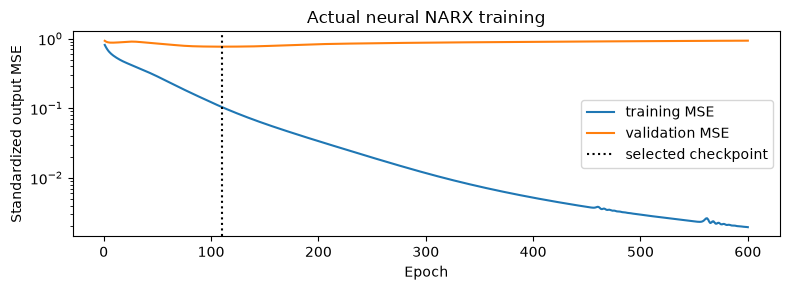

In [3]:
display({'gradient_boosted': baseline_metrics, 'neural_narx': neural_metrics})
loss = np.load(OUT/'neural'/'training_loss.npy')
fig, ax = plt.subplots(figsize=(8,3))
ax.semilogy(loss[:,0], loss[:,1], label='training MSE')
ax.semilogy(loss[:,0], loss[:,2], label='validation MSE')
ax.axvline(neural_metrics['selected_epoch'], color='k', ls=':', label='selected checkpoint')
ax.set(xlabel='Epoch', ylabel='Standardized output MSE', title='Actual neural NARX training')
ax.legend(); fig.tight_layout()
fig.savefig(OUT/'training_loss.png', dpi=160)
plt.show()

## Paired nonlinear 365-day station-keeping

Each of five independent annual trials reuses exactly the same physical initial state,
initial navigation error, covariance and epoch-indexed standard-normal optical draws
for all four controllers. Noise is indexed by sensor and epoch rather than consumed
only on accepted measurements; visibility may legitimately differ as trajectories diverge.
No learned policy invokes the STM at deployment. Truth and estimator receive the same
known observer impulse; there is no execution-error model. The prescribed Gateway never burns.

Termination occurs on a >20,000 km observer departure, nonfinite navigation/model output,
or an integration/numerical exception. Missing post-termination epochs stay NaN and count
as unsuccessful. Full-span completion and corridor compliance (100 km and 1 m/s) are
separate outcomes. RMSE on a terminated arc describes only its simulated portion.

In [4]:
summary = run_paired_study(cfg, OUT, baseline, days=YEAR_DAYS, arcs=MC_ARCS,
    seed=24017, measurement_cadence_s=21600., decisions_per_period=8,
    neural_bundle=neural)
display(summary['aggregate'])
policies = summary['controllers']
labels = dict(uncontrolled='Uncontrolled', stm='STM', narx='Gradient-boosted', neural_narx='Neural NARX')
colors = dict(uncontrolled='gray', stm='tab:blue', narx='tab:orange', neural_narx='tab:green')
episodes = {p: [dict(np.load(OUT/f'{p}_arc_{a:03d}.npz')) for a in range(MC_ARCS)] for p in policies}
print('Termination reasons and per-arc metrics:')
for row in summary['arc_metrics']:
    print(row['controller'], row['arc'], 'complete:', row['completed_full_span'],
          'corridor fraction:', round(row['corridor_fraction'],3),
          'dv m/s:', round(row['delta_v_total_m_s'],3), 'stop:', row['halted_reason'])
rows = []
for p in policies:
    selected = [r for r in summary['arc_metrics'] if r['controller']==p]
    completed = sum(r['completed_full_span'] for r in selected)
    maintained = sum(r['maintained_corridor_full_year'] for r in selected)
    rows.append(f"| {labels[p]} | {completed}/{MC_ARCS} | {maintained}/{MC_ARCS} | {summary['aggregate'][p]['median_total_delta_v_m_s']:.3f} |")
display(Markdown('| Controller | 365-day completion | Full-year corridor | Median simulated-span delta-v [m/s] |\n|---|---:|---:|---:|\n'+'\n'.join(rows)))
recall = neural_metrics['splits']['test']['recursive']['recall']
rmse = neural_metrics['splits']['test']['recursive']['feasible_burn_rmse_m_s']
if rmse is not None:
    display(Markdown(f'On the held-out teacher trajectories, recursive neural feasible-burn RMSE is **{rmse:.3f} m/s** and feasible-command recall is **{recall:.1%}**. Missed burn opportunities are therefore an observed limitation, in addition to possible recursive extrapolation. Smaller fuel totals for terminated arcs are not annual fuel savings.'))


arc 1/5 uncontrolled: completed=False, corridor=1.37%, delta_v=0.000 m/s
arc 1/5 stm: completed=True, corridor=92.86%, delta_v=39.806 m/s
arc 1/5 narx: completed=False, corridor=1.37%, delta_v=13.326 m/s
arc 1/5 neural_narx: completed=False, corridor=1.37%, delta_v=4.836 m/s
arc 2/5 uncontrolled: completed=False, corridor=2.20%, delta_v=0.000 m/s
arc 2/5 stm: completed=True, corridor=93.13%, delta_v=36.948 m/s
arc 2/5 narx: completed=False, corridor=1.92%, delta_v=18.412 m/s
arc 2/5 neural_narx: completed=False, corridor=2.20%, delta_v=6.127 m/s
arc 3/5 uncontrolled: completed=False, corridor=2.47%, delta_v=0.000 m/s
arc 3/5 stm: completed=True, corridor=92.58%, delta_v=38.809 m/s
arc 3/5 narx: completed=False, corridor=2.75%, delta_v=15.042 m/s
arc 3/5 neural_narx: completed=False, corridor=2.75%, delta_v=4.662 m/s
arc 4/5 uncontrolled: completed=False, corridor=1.10%, delta_v=0.000 m/s
arc 4/5 stm: completed=True, corridor=93.13%, delta_v=40.938 m/s
arc 4/5 narx: completed=False, cor

{'uncontrolled': {'arcs': 5,
  'full_span_completion_rate': 0.0,
  'full_year_corridor_success_rate': 0.0,
  'median_total_delta_v_m_s': 0.0,
  'median_gateway_position_rmse_km': 1.4951200025990772},
 'stm': {'arcs': 5,
  'full_span_completion_rate': 1.0,
  'full_year_corridor_success_rate': 0.0,
  'median_total_delta_v_m_s': 38.809061902317644,
  'median_gateway_position_rmse_km': 0.5443635902266698},
 'narx': {'arcs': 5,
  'full_span_completion_rate': 0.0,
  'full_year_corridor_success_rate': 0.0,
  'median_total_delta_v_m_s': 13.32564264617714,
  'median_gateway_position_rmse_km': 1.4799579438144959},
 'neural_narx': {'arcs': 5,
  'full_span_completion_rate': 0.0,
  'full_year_corridor_success_rate': 0.0,
  'median_total_delta_v_m_s': 6.1272987284585465,
  'median_gateway_position_rmse_km': 1.719494359162377}}

| Controller | 365-day completion | Full-year corridor | Median simulated-span delta-v [m/s] |
|---|---:|---:|---:|
| Uncontrolled | 0/5 | 0/5 | 0.000 |
| STM | 5/5 | 0/5 | 38.809 |
| Gradient-boosted | 0/5 | 0/5 | 13.326 |
| Neural NARX | 0/5 | 0/5 | 6.127 |

On the held-out teacher trajectories, recursive neural feasible-burn RMSE is **0.304 m/s** and feasible-command recall is **11.1%**. Missed burn opportunities are therefore an observed limitation, in addition to possible recursive extrapolation. Smaller fuel totals for terminated arcs are not annual fuel savings.

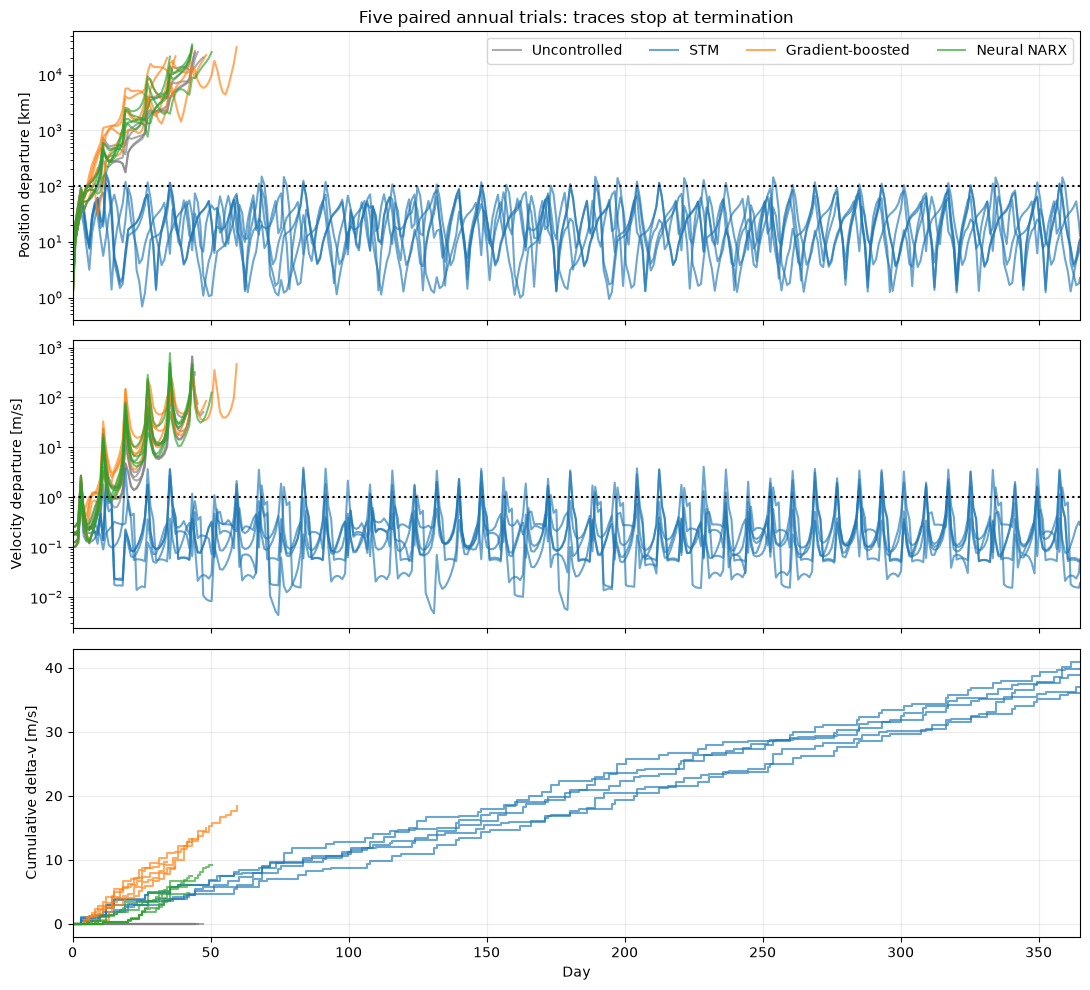

In [5]:
fig, axes = plt.subplots(3,1,figsize=(11,10),sharex=True)
for p in policies:
    for a,e in enumerate(episodes[p]):
        valid = np.isfinite(e['observer_truth_position_departure_km'])
        day = e['day'][valid]
        axes[0].plot(day,e['observer_truth_position_departure_km'][valid],color=colors[p],alpha=.65,label=labels[p] if a==0 else None)
        axes[1].plot(day,e['observer_truth_velocity_departure_m_s'][valid],color=colors[p],alpha=.65)
        axes[2].step(day,np.cumsum(e['delta_v_cost_m_s'])[valid],where='post',color=colors[p],alpha=.65)
axes[0].axhline(100,color='k',ls=':'); axes[1].axhline(1,color='k',ls=':')
axes[0].set(yscale='log',ylabel='Position departure [km]',title='Five paired annual trials: traces stop at termination')
axes[1].set(yscale='log',ylabel='Velocity departure [m/s]')
axes[2].set(xlabel='Day',ylabel='Cumulative delta-v [m/s]',xlim=(0,365))
axes[0].legend(ncol=4)
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT/'departure_and_delta_v.png',dpi=160); plt.show()

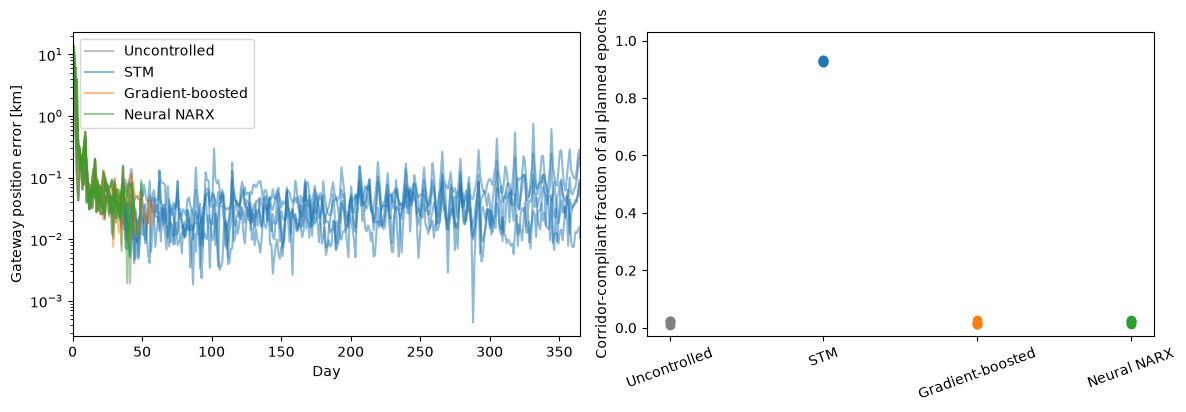

In [6]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for p in policies:
    for a,e in enumerate(episodes[p]):
        axes[0].plot(e['day'],e['gateway_tracking_position_error_km'],color=colors[p],alpha=.5,label=labels[p] if a==0 else None)
    rows = [r for r in summary['arc_metrics'] if r['controller']==p]
    axes[1].scatter([labels[p]]*len(rows),[r['corridor_fraction'] for r in rows],color=colors[p])
axes[0].set(yscale='log',xlabel='Day',ylabel='Gateway position error [km]',xlim=(0,365))
axes[0].legend(); axes[1].set(ylabel='Corridor-compliant fraction of all planned epochs',ylim=(-.03,1.03))
axes[1].tick_params(axis='x',rotation=20)
fig.tight_layout(); fig.savefig(OUT/'tracking_and_compliance.png',dpi=160); plt.show()

## Failure diagnostics and interpretation

The next plots expose execute scores, recursive feedback growth, input extrapolation
relative to training scaling, and command rejection. A large standardized input is an
extrapolation indicator, not a calibrated uncertainty bound. All terminations and valid
sample counts are recorded in `arc_metrics.csv`; uncomputed epochs are never filled in.
A failed controller can show a smaller total Δv simply because its simulation ended early.

Notebook 00 SHA-256 unchanged: 12a844876db323dfc56ea81abd44366589c8ec5a4e52b8193f0b1e951e0235b5


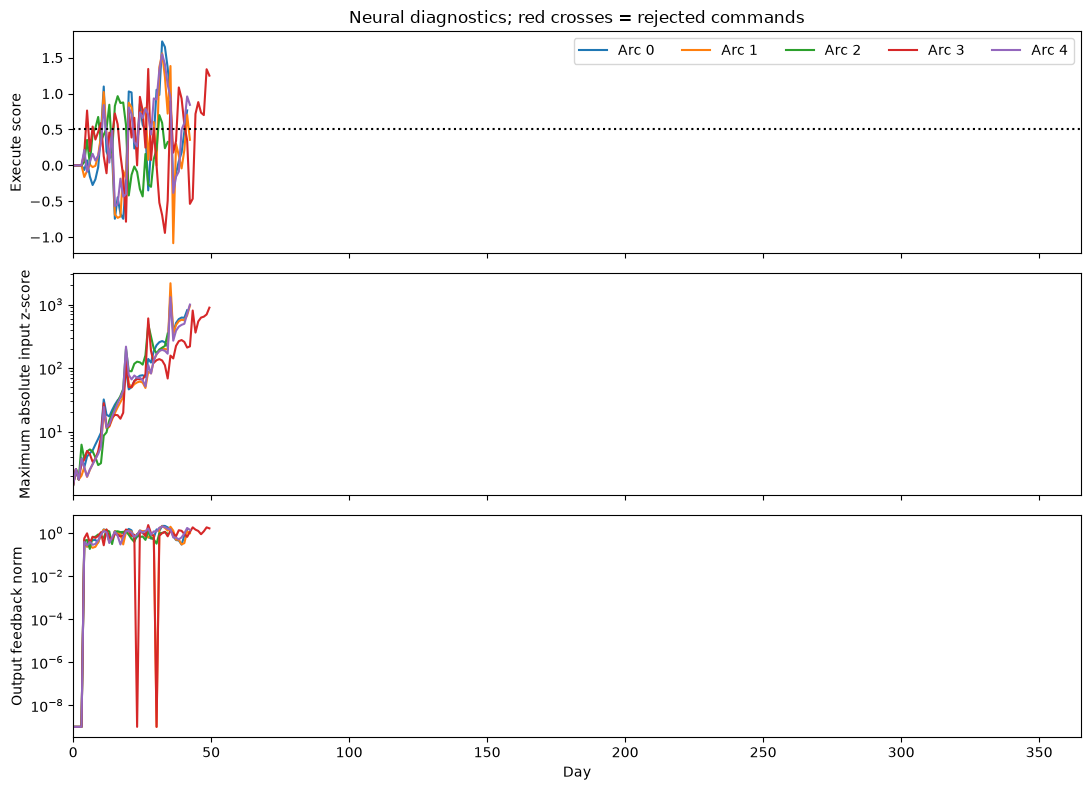

{'numpy': '2.5.4',
 'scipy': '1.18.1',
 'torch': '2.14.1',
 'narxpy': '0.1.0',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2',
 'nbformat': '5.11.1',
 'nbclient': '0.11.0'}

In [7]:
fig, axes = plt.subplots(3,1,figsize=(11,8),sharex=True)
for a,e in enumerate(episodes['neural_narx']):
    axes[0].plot(e['day'],e['neural_gate_score'],label=f'Arc {a}')
    axes[1].semilogy(e['day'],np.maximum(e['neural_input_max_abs_z'],1e-9))
    axes[2].semilogy(e['day'],np.maximum(e['neural_feedback_norm'],1e-9))
    rejected = e['maneuver_rejected']
    axes[0].scatter(e['day'][rejected],e['neural_gate_score'][rejected],marker='x',color='red')
axes[0].axhline(.5,color='k',ls=':'); axes[0].set(ylabel='Execute score',title='Neural diagnostics; red crosses = rejected commands')
axes[1].set(ylabel='Maximum absolute input z-score')
axes[2].set(ylabel='Output feedback norm',xlabel='Day',xlim=(0,365))
axes[0].legend(ncol=5)
fig.tight_layout(); fig.savefig(OUT/'neural_failure_diagnostics.png',dpi=160); plt.show()
assert hashlib.sha256(nb00.read_bytes()).hexdigest() == nb00_hash
print('Notebook 00 SHA-256 unchanged:', nb00_hash)
(OUT/'configuration.json').write_text(json.dumps(cfg,indent=2))
import importlib.metadata as metadata
versions = {p:metadata.version(p) for p in ('numpy','scipy','torch','narxpy','scikit-learn','matplotlib','nbformat','nbclient')}
(OUT/'versions.json').write_text(json.dumps({'python':platform.python_version(),**versions},indent=2))
display(versions)

## Why STM and learned NARX behave differently

STM recomputes a local maneuver from the current estimated state and orbit phase, then
checks it against the nonlinear CR3BP at a common future epoch. It can adapt to states
outside the short teacher arcs, although it still suffers from navigation error,
linearization error, impulse caps and sparse decision opportunities.

The neural NARX approximates that conditional command map from only 20 short teacher arcs.
Its past output taps create genuine recursive dependence: small prediction errors can
change later commands, burn timing, visibility and navigation. Teacher forcing supplies
correct past commands during training; autonomous prediction supplies imperfect ones.
Low offline RMSE therefore need not imply stable physical control. Classification and
argmax timing introduce additional discontinuities; waiting for a burn suppresses later
opportunities. Unstable halo dynamics can amplify early errors or four-decision startup
coasting into large departure. The baseline has related imitation and coverage limits,
but uses executed-impulse history rather than recursive neural scores.

Read the measured completion rates, corridor fractions, termination reasons, Δv and
extrapolation diagnostics above together. This experiment establishes executable neural
NARX control and measures its limitations; it does not assume NARX must outperform STM.
Five annual trials and the idealized CR3BP/sensor assumptions limit generalization.
Improved training coverage, recursive training, navigation-aware guidance and larger
independent ensembles require a new held-out evaluation rather than tuning to these trials.